In [18]:
# Imports and config
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

import sys
sys.path.append("..")  # Ensure parent dir is in path
from data.data_loader import DataLoader
from data.data_configs import SUBJECTS

### Load Data

In [19]:
# Load features using DataLoader
X, y, feature_names, subject_ids = DataLoader.load_features(SUBJECTS, mode="advanced")
print(f"Loaded features for {len(subject_ids)} samples from {len(SUBJECTS)} subject(s)")
print(f"X shape: {X.shape}, y shape: {y.shape}")

Loaded features for 62525 samples from 16 subject(s)
X shape: (62525, 240), y shape: (62525,)


In [20]:
print("Label distribution (%):")
print(pd.Series(y).value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

Label distribution (%):
False    56.04%
True     43.96%
Name: proportion, dtype: object


In [21]:
# Check for NaNs
n_nans = np.isnan(X).sum()
print(f"Number of NaNs in X: {n_nans}")
if n_nans > 0:
    print("Imputing NaNs with feature mean...")
    imputer = SimpleImputer(strategy="mean")
    X = imputer.fit_transform(X)
    print(f"Number of NaNs after imputation: {np.isnan(X).sum()}")
else:
    print("No NaNs found in X.")

# Check for infinite values
n_infs = np.isinf(X).sum()
print(f"Number of infinite values in X: {n_infs}")
if n_infs > 0:
    print("Replacing infinite values with feature mean...")
    X[np.isinf(X)] = np.nan
    imputer = SimpleImputer(strategy="mean")
    X = imputer.fit_transform(X)
    print(f"Number of infinite values after replacement: {np.isinf(X).sum()}")

# Scale features if needed
scaler = StandardScaler()
X = scaler.fit_transform(X)

Number of NaNs in X: 0
No NaNs found in X.
Number of infinite values in X: 0


In [22]:
# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Train shape: (50020, 240), Test shape: (12505, 240)


### SVM

SVM Results:
              precision    recall  f1-score   support

       False       0.60      0.81      0.69      7007
        True       0.56      0.31      0.40      5498

    accuracy                           0.59     12505
   macro avg       0.58      0.56      0.54     12505
weighted avg       0.58      0.59      0.56     12505

Accuracy: 0.591


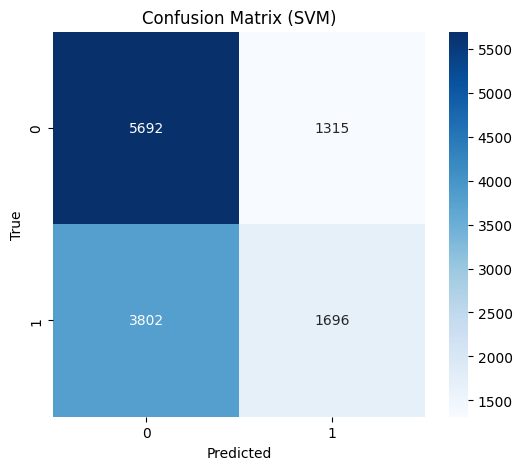

In [23]:
svm_clf = SVC(kernel="rbf", C=1.0, random_state=42)
svm_clf.fit(X_train, y_train)

y_pred_svm = svm_clf.predict(X_test)

print("SVM Results:")
print(classification_report(y_test, y_pred_svm))
print(f"Accuracy: {accuracy_score(y_test, y_pred_svm):.3f}")

# Confusion matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix (SVM)")
plt.show()

### RF

Random Forest Results:
              precision    recall  f1-score   support

       False       0.65      0.78      0.70      7007
        True       0.62      0.46      0.52      5498

    accuracy                           0.64     12505
   macro avg       0.63      0.62      0.61     12505
weighted avg       0.63      0.64      0.63     12505

Accuracy: 0.636


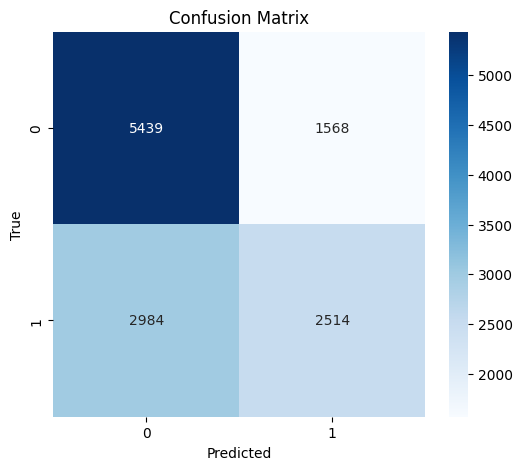

In [24]:
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)


y_pred = clf.predict(X_test)

print("Random Forest Results:")
print(classification_report(y_test, y_pred))
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

# Only Eyetracking data
This just uses fixation duration. Maybe add Saccade features.

In [25]:
et_df = DataLoader.load_labeled_et_data(SUBJECTS)

print(et_df["duration_ms"].isna().sum())
print(et_df["fixation_on_airplane"].isna().sum())

0
0


In [26]:
print("Label distribution:")
print(et_df["fixation_on_airplane"].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

Label distribution:
fixation_on_airplane
False    56.03%
True     43.97%
Name: proportion, dtype: object


In [27]:
X_et = et_df[["duration_ms"]].values
y_et = et_df["fixation_on_airplane"].astype(int).values

# Train/test split
X_et_train, X_et_test, y_et_train, y_et_test = train_test_split(X_et, y_et, test_size=0.2, random_state=42, stratify=y_et)

Random Forest on Eyetracking duration_ms:
              precision    recall  f1-score   support

           0       0.58      0.60      0.59      7008
           1       0.46      0.44      0.45      5498

    accuracy                           0.53     12506
   macro avg       0.52      0.52      0.52     12506
weighted avg       0.53      0.53      0.53     12506

Accuracy: 0.529


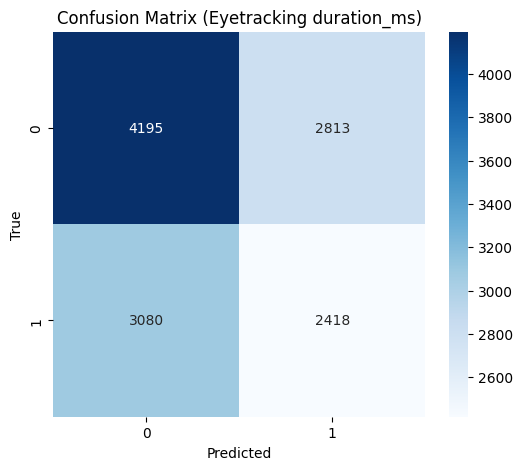

In [29]:
# Train and evaluate Random Forest
clf_et = RandomForestClassifier(n_estimators=100, random_state=42)
clf_et.fit(X_et_train, y_et_train)
y_et_pred = clf_et.predict(X_et_test)

print("Random Forest on Eyetracking duration_ms:")
print(classification_report(y_et_test, y_et_pred))
print(f"Accuracy: {accuracy_score(y_et_test, y_et_pred):.3f}")

# Confusion matrix
cm_et = confusion_matrix(y_et_test, y_et_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_et, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix (Eyetracking duration_ms)")
plt.show()